# Семинар 2. Метрики, решения и поиск соседей
**Цель:** оценивать нужные ошибки, выбирать порог без утечки и понимать, когда расстояния и поиск соседей полезны.

План: baseline и матрица ошибок → предобработка → scores, ROC и PR → выбор модели и порога → k-d tree → multiclass → отбор признаков.

Данные: локальный Telco Customer Churn CSV. Положительный класс **1 = Churn Yes**.
Представим, что положительное предсказание приводит к предложению удержания клиента:
FP — предложение клиенту, который не ушёл; FN — пропущенный уходящий клиент.

Нужны NumPy, pandas, Matplotlib, scikit-learn. При необходимости установите их отдельно через `%pip install numpy pandas matplotlib scikit-learn` и перезапустите ядро.

In [1]:
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
)
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors, KDTree
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    auc,
)
from sklearn.datasets import make_classification, make_blobs
from sklearn.feature_selection import SequentialFeatureSelector

SEED = 42
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True})

## 1. Сначала отложим test
Заполнение пропусков, статистики масштабирования и словарь категорий нужно обучать только на train.
Не просматриваем test для выбора решений. Число строк печатаем для проверки разбиения.

In [2]:
candidates = [
    Path("WA_Fn-UseC_-Telco-Customer-Churn (1).csv"),
    Path("WA_Fn-UseC_-Telco-Customer-Churn.csv"),
]
data_path = next((p for p in candidates if p.exists()), None)
if data_path is None:
    raise FileNotFoundError(
        "Положите Telco Customer Churn CSV рядом с notebook."
    )
data = pd.read_csv(data_path)
X = data.drop(columns=["customerID", "Churn"]).copy()
X["TotalCharges"] = pd.to_numeric(X["TotalCharges"], errors="coerce")
y = data["Churn"].map({"No": 0, "Yes": 1})
assert y.notna().all(), "Неожиданные метки Churn"
# ID не является содержательным измерением для расстояния; исключаем его
# заранее.
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=SEED
)
print("train / validation / test:", len(X_train), len(X_val), len(X_test))
print("Train: доля Churn Yes =", round(y_train.mean(), 3))
X_train.head()

train / validation / test: 4225 1409 1409
Train: доля Churn Yes = 0.265


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
2312,Male,0,No,No,18,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,No,Mailed check,20.10,401.85
5227,Male,0,No,No,7,Yes,Yes,Fiber optic,No,No,No,No,Yes,Yes,Month-to-month,No,Electronic check,96.20,639.70
6404,Male,0,No,No,52,Yes,Yes,Fiber optic,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Electronic check,109.30,5731.40
88,Female,0,Yes,Yes,46,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,Yes,Mailed check,19.95,927.10
6496,Male,1,Yes,No,40,Yes,Yes,Fiber optic,Yes,No,No,No,Yes,Yes,Month-to-month,No,Electronic check,101.85,4086.30


### Baseline: всегда «не уйдёт» (`churn=1`)
Предскажите accuracy, precision и recall такого правила. Высокая accuracy сама по себе
не означает, что мы нашли уходящих клиентов. При отсутствии положительных предсказаний
precision математически не определена; ниже явно используем соглашение `zero_division=0`.

In [3]:
def metric_row(name, truth, prediction):
    return {
        "rule": name,
        "accuracy": accuracy_score(truth, prediction),
        "precision": precision_score(truth, prediction, zero_division=0),
        "recall": recall_score(truth, prediction, zero_division=0),
        "F1": f1_score(truth, prediction, zero_division=0),
    }


baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
baseline_val = baseline.predict(X_val)
pd.DataFrame([metric_row("Always No", y_val, baseline_val)])

,rule,accuracy,precision,recall,F1
0,Always No,0.734564,0.0,0.0,0.0


### Матрица ошибок: сначала проверьте оси
**В scikit-learn:** строки — истина, столбцы — предсказание:

| Истина \ Предсказание | 0 | 1 |
|---|---|---|
| 0 | TN | FP |
| 1 | FN | TP |


**Метрики положительного класса:**

$$\mathrm{Precision} = \frac{TP}{TP + FP}$$
Среди предсказанных положительных — доля действительно положительных.

$$\mathrm{Recall} = \mathrm{TPR} = \frac{TP}{TP + FN}$$
Среди действительно положительных — доля найденных моделью.

$$\mathrm{FPR} = \frac{FP}{FP + TN}$$
Среди действительно отрицательных — доля ошибочно предсказанных положительными.

При нулевом знаменателе соответствующая метрика не определена; соглашение для
таких случаев нужно задавать явно.

`normalize="true"` делит каждую строку на число объектов истинного класса;
деление всей матрицы на n даёт доли всех объектов, а не class-conditional rates.

{'TN': 3, 'FP': 2, 'FN': 1, 'TP': 2}
Precision: 0.5 Recall: 0.6666666666666666 FPR: 0.4


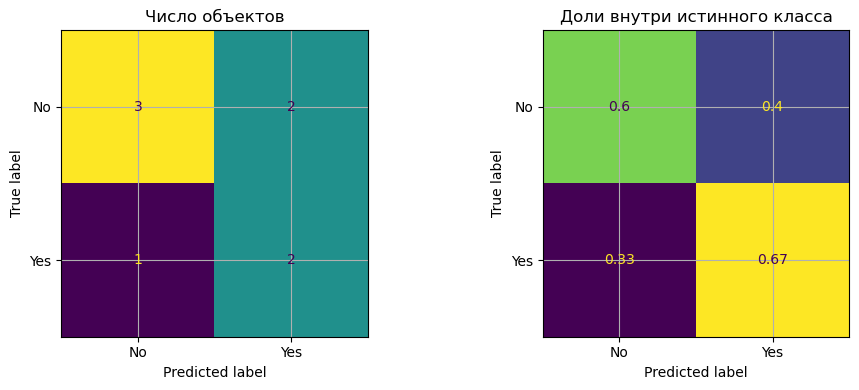

In [4]:
toy_true = np.array([1, 1, 1, 0, 0, 0, 0, 0])
toy_pred = np.array([1, 0, 1, 1, 0, 0, 1, 0])
tn, fp, fn, tp = confusion_matrix(toy_true, toy_pred, labels=[0, 1]).ravel()
print(dict(TN=tn, FP=fp, FN=fn, TP=tp))
print(
    "Precision:",
    tp / (tp + fp),
    "Recall:",
    tp / (tp + fn),
    "FPR:",
    fp / (fp + tn),
)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for norm, title, ax in zip(
    [None, "true"], ["Число объектов", "Доли внутри истинного класса"], axes
):
    ConfusionMatrixDisplay.from_predictions(
        toy_true,
        toy_pred,
        labels=[0, 1],
        display_labels=["No", "Yes"],
        normalize=norm,
        ax=ax,
        colorbar=False,
    )
    ax.set_title(title)
plt.tight_layout()
plt.show()

## 2. Предобработка — часть обучения
Рассматриваем **только train**: какие типы признаков и пропуски есть?
Проверьте tenure у клиентов с пропущенным TotalCharges: здесь это новые клиенты
с tenure=0. В качестве baseline заполняем TotalCharges нулём, предполагая, что
накопленные платежи ещё не сформированы. Это явно выбранная гипотеза, а не
универсальное правило для пропусков. У остальных числовых признаков здесь пропусков нет.

In [5]:
numeric = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical = [col for col in X_train.columns if col not in numeric]
print(X_train[numeric].isna().sum())
print(
    "tenure у train-объектов с пропуском TotalCharges:",
    X_train.loc[X_train.TotalCharges.isna(), "tenure"].unique(),
)
print("Число категорий (train):")
print(X_train[categorical].nunique())

tenure            0
MonthlyCharges    0
TotalCharges      7
dtype: int64
tenure у train-объектов с пропуском TotalCharges: [0]
Число категорий (train):
gender              2
SeniorCitizen       2
Partner             2
Dependents          2
PhoneService        2
MultipleLines       3
InternetService     3
OnlineSecurity      3
OnlineBackup        3
DeviceProtection    3
TechSupport         3
StreamingTV         3
StreamingMovies     3
Contract            3
PaperlessBilling    2
PaymentMethod       4
dtype: int64


Числовые столбцы: `SimpleImputer(strategy="constant", fill_value=0)` → `StandardScaler`.
В этом наборе числовые пропуски есть только в TotalCharges; используем ноль как baseline.
Категориальные: заполнение пропусков → полный one-hot, включая SeniorCitizen.

`handle_unknown="ignore"` позволяет обработать новую категорию как нулевой блок.

Не масштабируем dummy-столбцы по их стандартному отклонению: это дополнительно
усиливало бы редкие категории (из-за деления на стандартное отклонение).
Pipeline внутри CV заново обучает **всю** предобработку в каждом фолде.

In [38]:
def make_preprocessor():
    numeric_pipe = make_pipeline(
        SimpleImputer(strategy="constant", fill_value=0), StandardScaler()
    )
    categorical_pipe = make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        OneHotEncoder(handle_unknown="ignore"),
    )
    return ColumnTransformer(
        [
            ("numeric", numeric_pipe, numeric),
            ("categorical", categorical_pipe, categorical),
            # sparse_threshold - for sparse representation of encoded columns
        ],
        sparse_threshold=0,
    )


def make_churn_model(k=21):
    return Pipeline(
        [
            ("preprocess", make_preprocessor()),
            ("knn", KNeighborsClassifier(n_neighbors=k, algorithm="brute")),
        ]
    )


illustration = make_churn_model().fit(X_train, y_train)
val_labels = illustration.predict(X_val)
pd.DataFrame(
    [
        metric_row("Always No", y_val, baseline_val),
        metric_row("21-NN, default", y_val, val_labels),
    ]
)

,rule,accuracy,precision,recall,F1
0,Always No,0.734564,0.000000,0.000000,0.000000
1,"21-NN, default",0.787793,0.613293,0.542781,0.575887


## 3. Score → порог → решение
kNN выдаёт долю голосов положительного класса. При k=1 возможны только scores 0 и 1; для изучения порогов берём k=21.
Фиксируем правило: **предсказываем 1, если score ≥ threshold**.

In [39]:
one_nn = make_churn_model(k=1).fit(X_train, y_train)
print("Scores 1-NN:", np.unique(one_nn.predict_proba(X_val)[:, 1]))
val_scores = illustration.predict_proba(X_val)[:, 1]
print("Число разных scores 21-NN:", len(np.unique(val_scores)))


def threshold_table(truth, scores):
    rows = []
    for threshold in np.r_[np.inf, np.sort(np.unique(scores))[::-1]]:
        prediction = scores >= threshold
        tn, fp, fn, tp = confusion_matrix(
            truth, prediction, labels=[0, 1]
        ).ravel()
        rows.append(
            {
                "threshold": threshold,
                "TP": tp,
                "FP": fp,
                "FN": fn,
                "TN": tn,
                **{
                    k: v
                    for k, v in metric_row("", truth, prediction).items()
                    if k != "rule"
                },
                "FPR": fp / (fp + tn),
            }
        )
    return pd.DataFrame(rows)


thresholds = threshold_table(y_val, val_scores)
thresholds.round(3)

Scores 1-NN: [0. 1.]
Число разных scores 21-NN: 22


,threshold,TP,FP,FN,TN,accuracy,precision,recall,F1,FPR
0,inf,0,0,374,1035,0.735,0.000,0.000,0.000,0.000
1,1.000,1,0,373,1035,0.735,1.000,0.003,0.005,0.000
2,0.952,1,1,373,1034,0.735,0.500,0.003,0.005,0.001
3,0.905,12,3,362,1032,0.741,0.800,0.032,0.062,0.003
4,0.857,24,9,350,1026,0.745,0.727,0.064,0.118,0.009
5,0.810,40,15,334,1020,0.752,0.727,0.107,0.186,0.014
6,0.762,60,22,314,1013,0.762,0.732,0.160,0.263,0.021
7,0.714,90,34,284,1001,0.774,0.726,0.241,0.361,0.033
8,0.667,113,53,261,982,0.777,0.681,0.302,0.419,0.051
9,0.619,143,76,231,959,0.782,0.653,0.382,0.482,0.073


### ROC и Precision–Recall
ROC: TPR против FPR. PR: precision против recall. Меняя порог, двигаемся по кривым,
но не переобучаем модель. Сначала найдите в таблице строку с threshold около 0.5.

Для случайного ранжирования ROC-baseline — диагональ; PR-baseline — доля положительного класса.
PR-AUC — площадь под PR-кривой. В этом семинаре соединяем точки кривой отрезками
и вычисляем площадь: `auc(recall, precision)`.


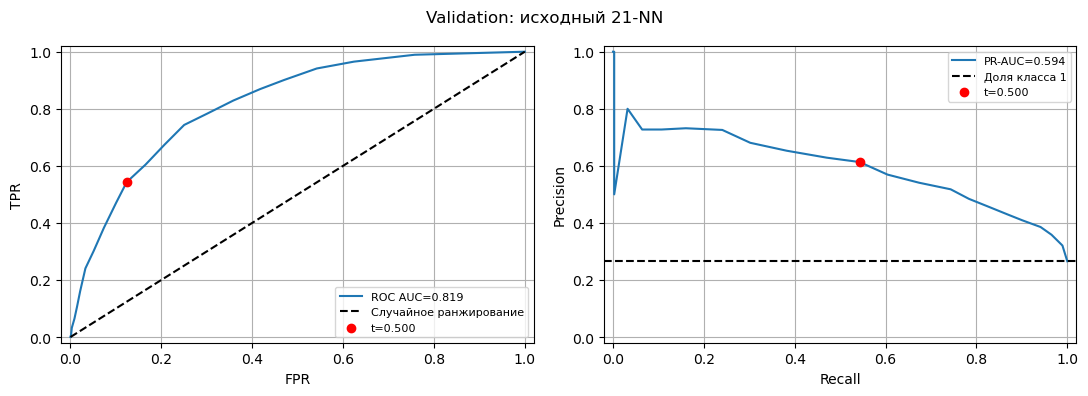

In [40]:
def pr_auc(truth, scores):
    precision, recall, _ = precision_recall_curve(truth, scores)
    return auc(recall, precision)


def pr_auc_scorer(estimator, features, truth):
    # GridSearchCV передаёт модель, validation-фолд и его метки.
    # Кривую строим по scores, а не по предсказанным классам.
    scores = estimator.predict_proba(features)[:, 1]
    return pr_auc(truth, scores)


def draw_curves(truth, scores, title, threshold=None):
    fpr, tpr, _ = roc_curve(truth, scores)
    precision, recall, _ = precision_recall_curve(truth, scores)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(fpr, tpr, label=f"ROC AUC={roc_auc_score(truth, scores):.3f}")
    axes[0].plot([0, 1], [0, 1], "k--", label="Случайное ранжирование")
    axes[1].plot(
        recall, precision, label=f"PR-AUC={auc(recall, precision):.3f}"
    )
    axes[1].axhline(
        np.mean(truth), color="black", ls="--", label="Доля класса 1"
    )
    if threshold is not None:
        pred = scores >= threshold
        tn, fp, fn, tp = confusion_matrix(truth, pred, labels=[0, 1]).ravel()
        axes[0].scatter(
            fp / (fp + tn),
            tp / (tp + fn),
            c="red",
            zorder=5,
            label=f"t={threshold:.3f}",
        )
        axes[1].scatter(
            recall_score(truth, pred),
            precision_score(truth, pred, zero_division=0),
            c="red",
            zorder=5,
            label=f"t={threshold:.3f}",
        )
    axes[0].set(xlabel="FPR", ylabel="TPR")
    axes[1].set(xlabel="Recall", ylabel="Precision")
    for ax in axes:
        ax.set(xlim=(-0.02, 1.02), ylim=(-0.02, 1.02))
        ax.legend(fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


draw_curves(y_val, val_scores, "Validation: исходный 21-NN", threshold=0.5)

## 4. Выбираем модель и порог раздельно
На **train** выбираем k, метрику расстояния и веса с помощью CV.
Критерий — PR-AUC: хотим получить полезное ранжирование для последующего выбора порога.
Это заранее выбранная учебная цель, а не универсальный критерий churn.

После CV лучшая модель переобучается на всём **train, переданном в fit**.
Validation используется затем для выбора порога.
Сетка небольшая, для примера.

In [41]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
search = GridSearchCV(
    make_churn_model(),
    {
        "knn__n_neighbors": [7, 21, 41],
        "knn__p": [1, 2],
        "knn__weights": ["uniform", "distance"],
        # refit=True - refit on all folds
    },
    scoring=pr_auc_scorer,
    cv=cv,
    refit=True,
    n_jobs=1,
)
search.fit(X_train, y_train)
print("Выбрано:", search.best_params_)
print(
    "Средняя CV PR-AUC (использована для выбора):",
    round(search.best_score_, 3),
)
cv_results = pd.DataFrame(search.cv_results_)
cv_results[["params", "mean_test_score", "std_test_score"]].sort_values(
    "mean_test_score", ascending=False
).head(6)

Выбрано: {'knn__n_neighbors': 41, 'knn__p': 1, 'knn__weights': 'uniform'}
Средняя CV PR-AUC (использована для выбора): 0.627


,params,mean_test_score,std_test_score
8,"{'knn__n_neighbors': 41, 'knn__p': 1, 'knn__we...",0.627488,0.001717
10,"{'knn__n_neighbors': 41, 'knn__p': 2, 'knn__we...",0.625055,0.003356
6,"{'knn__n_neighbors': 21, 'knn__p': 2, 'knn__we...",0.606861,0.008949
11,"{'knn__n_neighbors': 41, 'knn__p': 2, 'knn__we...",0.606213,0.011756
4,"{'knn__n_neighbors': 21, 'knn__p': 1, 'knn__we...",0.603486,0.007703
9,"{'knn__n_neighbors': 41, 'knn__p': 1, 'knn__we...",0.598464,0.013164


### Требование к решению: recall ≥ 0.8, затем максимальная precision
Число 0.8 — **иллюстративное требование**.
При равенстве precision выбираем больший порог. Если ни один порог не подходит,
сообщаем об этом.

Другие возможные критерии: `TPR − FPR`; ближайшая к левому верхнему углу
ROC точка. 

После настройки порога мы не добавляем validation в обучение: переобучение может изменить scores и работу порога.

threshold      0.317
TP           300.000
FP           320.000
FN            74.000
TN           715.000
accuracy       0.720
precision      0.484
recall         0.802
F1             0.604
FPR            0.309
Name: 25, dtype: float64


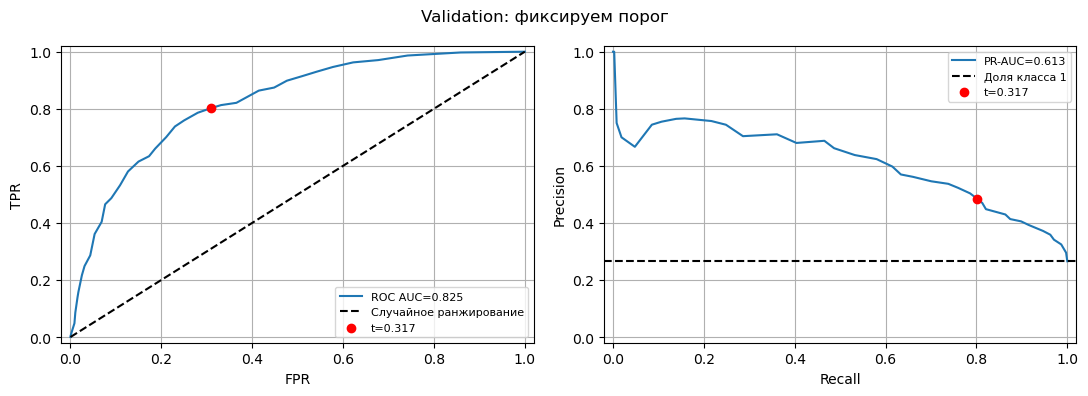

In [42]:
selected_model = search.best_estimator_
selected_val_scores = selected_model.predict_proba(X_val)[:, 1]
selection_table = threshold_table(y_val, selected_val_scores)
feasible = selection_table[selection_table.recall >= 0.8]
if feasible.empty:
    raise RuntimeError("Требование recall >= 0.8 недостижимо на validation")
chosen = feasible.sort_values(
    ["precision", "threshold"], ascending=False
).iloc[0]
chosen_threshold = float(chosen.threshold)
print(chosen.round(3))
draw_curves(
    y_val, selected_val_scores, "Validation: фиксируем порог", chosen_threshold
)

### Test: финальная проверка
Теперь модель и порог зафиксированы. Сравниваем baseline, порог 0.5 и выбранный порог
в одном заранее запланированном отчёте. Результаты test не используем для новых решений.
Достижение recall ≥ 0.8 на validation не гарантирует того же на новых данных.

                 rule  accuracy  precision  recall    F1
            Always No     0.735      0.000   0.000 0.000
  Chosen model, t=0.5     0.778      0.583   0.572 0.578
Chosen model, t=0.317     0.724      0.488   0.802 0.607
Test ROC AUC: 0.826 Test PR-AUC: 0.607


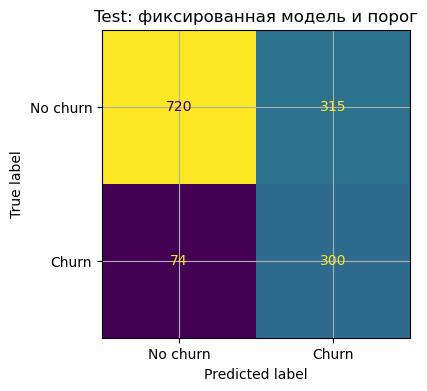

In [43]:
test_scores = selected_model.predict_proba(X_test)[:, 1]
test_default = test_scores >= 0.5
test_selected = test_scores >= chosen_threshold
print(
    pd.DataFrame(
        [
            metric_row("Always No", y_test, baseline.predict(X_test)),
            metric_row("Chosen model, t=0.5", y_test, test_default),
            metric_row(
                f"Chosen model, t={chosen_threshold:.3f}",
                y_test,
                test_selected,
            ),
        ]
    )
    .round(3)
    .to_string(index=False)
)
print(
    "Test ROC AUC:",
    round(roc_auc_score(y_test, test_scores), 3),
    "Test PR-AUC:",
    round(pr_auc(y_test, test_scores), 3),
)
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_selected,
    labels=[0, 1],
    display_labels=["No churn", "Churn"],
    colorbar=False,
)
plt.title("Test: фиксированная модель и порог")
plt.show()

## 5. k-d tree: сначала проследите точный поиск
Откройте [построение дерева и поиск в лекции](https://gvolsky.github.io/hse-ml-course/lecture2/).
На слайдах **How do we build a k-d tree?** и **When can we skip a whole region?**:
1. Определите ось разбиения и медианную точку.
2. Проследите спуск запроса к листу, обновляя лучшего кандидата.
3. При возврате сравните расстояние до разделяющей плоскости с лучшим расстоянием.
4. Если другая сторона может содержать более близкую точку, проверьте её.


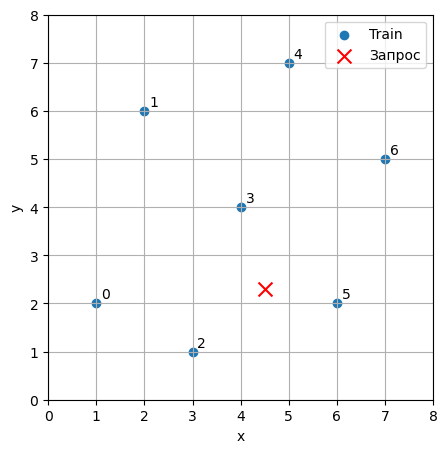

Ближайшая точка: 5 расстояние: 1.5297058540778354


In [45]:
tree_points = np.array(
    [
        [1.0, 2.0],
        [2.0, 6.0],
        [3.0, 1.0],
        [4.0, 4.0],
        [5.0, 7.0],
        [6.0, 2.0],
        [7.0, 5.0],
    ]
)
tree_query = np.array([[4.5, 2.3]])
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(tree_points[:, 0], tree_points[:, 1], label="Train")
for index, point in enumerate(tree_points):
    ax.annotate(str(index), point + 0.1)
ax.scatter(*tree_query[0], marker="x", c="red", s=100, label="Запрос")
ax.set(xlim=(0, 8), ylim=(0, 8), xlabel="x", ylabel="y")
ax.set_aspect("equal")
ax.legend()
plt.show()
# Сначала вручную: корневая медиана по x; затем медианы по y в обеих ветвях.
# Какие ветви надо проверить для этого запроса? Проверка ближайшего:
tree = KDTree(tree_points, leaf_size=1)
distance, index = tree.query(tree_query, k=1)
print("Ближайшая точка:", index[0, 0], "расстояние:", distance[0, 0])

## 6. Несколько классов: macro и micro
Строки матрицы ниже — истинные классы, столбцы — предсказанные (как в sklearn).
Вручную найдите recall редкого класса и сравните macro/micro precision и recall.

В **single-label multiclass** (у каждого объекта один истинный и один предсказанный класс)
<u>*при учёте всех классов*</u> **micro Precision = micro Recall = Accuracy**.

Для каждого класса $c$ считаем TP, FP и FN по правилу «этот класс против остальных».
При micro сначала суммируем эти числа по классам, затем вычисляем метрики:

$$
\mathrm{Precision}_{micro}
=\frac{\sum_c TP_c}{\sum_c TP_c+\sum_c FP_c},
\qquad
\mathrm{Recall}_{micro}
=\frac{\sum_c TP_c}{\sum_c TP_c+\sum_c FN_c}.
$$

Каждое **верное предсказание** добавляет один TP истинному классу.
Каждая **ошибка** добавляет один FN истинному классу и один FP предсказанному.
Например, истинный класс «личное письмо», предсказан «спам»: FN для личных писем,
FP для спама. Это одна ошибка объекта, учтённая в двух разных суммах.

Пусть всего объектов $N$, из них правильно классифицированы $C$. Тогда:

$$
\sum_c TP_c=C,\qquad \sum_c FP_c=\sum_c FN_c=N-C.
$$

Поэтому:

$$
\mathrm{Precision}_{micro}=\mathrm{Recall}_{micro}
=\frac{C}{C+(N-C)}=\frac{C}{N}=\mathrm{Accuracy}.
$$

Если считать micro только для части классов, некоторые FP или FN не попадут
в суммы и равенство с общей accuracy может нарушиться.

**Macro** даёт каждому классу одинаковый вес: сначала считаем метрику отдельно
для каждого класса, затем берём обычное среднее. Для $K$ классов:

$$
\mathrm{Precision}_{macro}=\frac{1}{K}\sum_{c=1}^{K}\mathrm{Precision}_c,
\qquad
\mathrm{Recall}_{macro}=\frac{1}{K}\sum_{c=1}^{K}\mathrm{Recall}_c.
$$

Редкий класс влияет на macro так же, как частый. **Weighted**, напротив,
усредняет с весами $n_c/N$, где $n_c$ — число объектов истинного класса $c$;
поэтому редкий класс влияет мало. Если редкие классы важны, смотрите macro
и метрики каждого класса отдельно.

In [46]:
multi_matrix = np.array([[54, 5, 1], [6, 22, 2], [4, 3, 3]])
multi_true, multi_pred = [], []
for true_class in range(3):
    for predicted_class in range(3):
        count = multi_matrix[true_class, predicted_class]
        multi_true.extend([true_class] * count)
        multi_pred.extend([predicted_class] * count)
for average in ["macro", "micro", "weighted"]:
    print(
        average,
        "precision:",
        round(precision_score(multi_true, multi_pred, average=average), 3),
        "recall:",
        round(recall_score(multi_true, multi_pred, average=average), 3),
    )
print("accuracy:", accuracy_score(multi_true, multi_pred))

macro precision: 0.692 recall: 0.644
micro precision: 0.79 recall: 0.79
weighted precision: 0.776 recall: 0.79
accuracy: 0.79


## 7. Жадный отбор признаков
На небольшом синтетическом наборе выбираем 2 из 8 признаков по CV **только на train**.
Scaler находится внутри estimator, поэтому обучается заново в каждом фолде отбора.
Это фиксированный бюджет в два признака, не правило остановки LOO из лекции.
Жадный отбор не гарантирует лучшее подмножество и может выбрать шум.
Оценка, использованная для отбора, не является независимой оценкой качества.
Здесь отдельная held-out выборка; churn test не используется.

In [50]:
feature_X, feature_y = make_classification(
    n_samples=240,
    n_features=8,
    n_informative=2,
    # n_redundant - linear combination of features
    n_redundant=0,
    shuffle=False,
    random_state=SEED,
)
fa, fb, ya, yb = train_test_split(
    feature_X, feature_y, test_size=0.3, stratify=feature_y, random_state=SEED
)
feature_estimator = make_pipeline(
    StandardScaler(), KNeighborsClassifier(n_neighbors=7)
)
selector = SequentialFeatureSelector(
    feature_estimator,
    n_features_to_select=2,
    direction="forward",
    scoring="accuracy",
    cv=StratifiedKFold(3, shuffle=True, random_state=SEED),
    n_jobs=1,
)
selector.fit(fa, ya)  # direction="forward" - start with 0
selected_features = selector.get_support(indices=True)
print("Выбраны признаки:", selected_features, "(информативные: 0 и 1)")
for name, indices in [
    ("Все:", np.arange(8)),
    ("Отобранные:", selected_features),
]:
    feature_estimator.fit(fa[:, indices], ya)
    print(
        name,
        "held-out accuracy =",
        round(feature_estimator.score(fb[:, indices], yb), 3),
    )

Выбраны признаки: [0 1] (информативные: 0 и 1)
Все: held-out accuracy = 0.889
Отобранные: held-out accuracy = 0.986


## 8. Удаление прототипов
Простое жадное удаление для 1-NN: удаляем объект, только если все исходные train-метки
по-прежнему воспроизводятся оставшимися точками. Проверка включает удалённые объекты.
Это учебный пример, **не эквивалентный оригинальному DROP5** и не *оптимальное минимальное множество*.
Безошибочность на train не гарантирует сохранения качества на held-out.
Порядок удаления влияет на результат. При равенстве расстояний действует правило sklearn.

Оставлено: 2 из 30


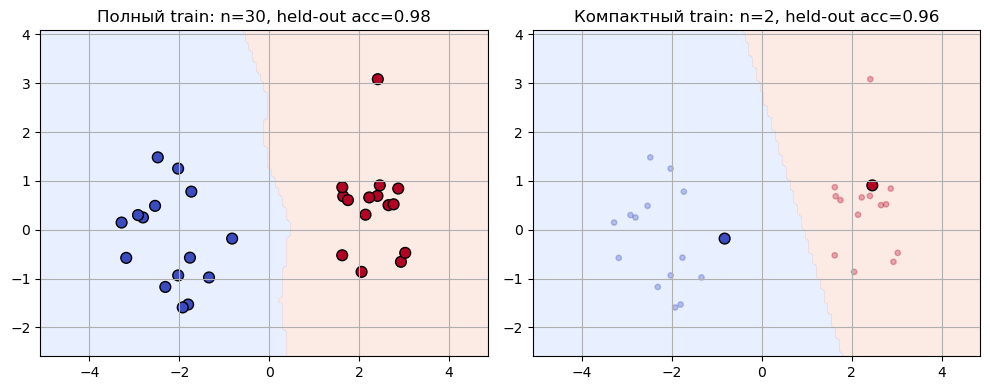

In [53]:
prototype_X, prototype_y = make_blobs(
    n_samples=160,
    centers=[[-2.0, 0.0], [2.0, 0.0]],
    cluster_std=0.8,
    random_state=SEED,
)
pa, pb, qa, qb = train_test_split(
    prototype_X,
    prototype_y,
    train_size=30,
    stratify=prototype_y,
    random_state=SEED,
)
kept = list(range(len(pa)))
for candidate in kept:
    trial = [index for index in kept if index != candidate]
    trial_model = KNeighborsClassifier(n_neighbors=1).fit(pa[trial], qa[trial])
    if np.array_equal(trial_model.predict(pa), qa):
        kept = trial
print("Оставлено:", len(kept), "из", len(pa))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
gx, gy = np.meshgrid(
    np.linspace(prototype_X[:, 0].min() - 1, prototype_X[:, 0].max() + 1, 120),
    np.linspace(prototype_X[:, 1].min() - 1, prototype_X[:, 1].max() + 1, 120),
)
for name, indices, ax in [
    ("Полный train", list(range(len(pa))), axes[0]),
    ("Компактный train", kept, axes[1]),
]:
    model = KNeighborsClassifier(n_neighbors=1).fit(pa[indices], qa[indices])
    regions = model.predict(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
    ax.contourf(
        gx, gy, regions, levels=[-0.5, 0.5, 1.5], cmap="coolwarm", alpha=0.2
    )
    ax.scatter(
        pa[:, 0],
        pa[:, 1],
        c=qa,
        cmap="coolwarm",
        vmin=0,
        vmax=1,
        s=15,
        alpha=0.3,
    )
    ax.scatter(
        pa[indices, 0],
        pa[indices, 1],
        c=qa[indices],
        cmap="coolwarm",
        vmin=0,
        vmax=1,
        edgecolors="black",
        s=60,
    )
    ax.set_title(
        f"{name}: n={len(indices)}, held-out acc={model.score(pb, qb):.2f}"
    )
plt.tight_layout()
plt.show()

### Материалы
- [Лекция 2](https://gvolsky.github.io/hse-ml-course/lecture2/)
- [sklearn: предотвращение утечек](https://scikit-learn.org/stable/common_pitfalls.html)
- [sklearn: выбор порога](https://scikit-learn.org/stable/modules/classification_threshold.html)
- [sklearn: метрики](https://scikit-learn.org/stable/modules/model_evaluation.html)